# Sex-stratified composition with verified sex labels

Checks the Results sentence "Descriptive comparisons showed no obvious systematic compositional shift by sex."
Sex labels were re-verified per sample against GEO / BioSample / EGA and the papers' supplementary tables
(`Comment1_sample_reconciliation/sex_verified.csv`): 208 of 257 samples have sex (92 female, 116 male), up from 141
in the atlas `Sex` column. All previously known values were confirmed; only Unknown -> Female/Male changes.

In [ ]:
import os
os.chdir('/workspace/PDAC_Work_Dir/PDAC_Final/Revision/scCoda')



In [ ]:
import anndata as ad
import numpy as np
import pandas as pd
import zarr
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# obs only: avoids loading the 1M x 38k matrix
obs = ad.io.read_elem(zarr.open('workspace/PDAC_Work_Dir/PDAC_Final/PDAC_Revisions_October/human_pdac_atlas_Harmonised.zarr', mode='r')['obs'])

# atlas Sample_ID is "<Sample_ID>_<Dataset_ID prefix>", e.g. HT056P1_Ding_2022 <-> Ding_2022_HT056P1
master = pd.read_csv('workspace/PDAC_Work_Dir/PDAC_Final/PDAC_Revisions_October/master_sample_list.csv')
master['atlas_sample'] = [f"{s}_{d[:-len(s) - 1]}" for s, d in zip(master['Sample_ID'].astype(str), master['Dataset_ID'])]
obs['Dataset_ID'] = obs['Sample_ID'].astype(str).map(master.set_index('atlas_sample')['Dataset_ID'])
assert obs['Dataset_ID'].notna().all()

# verified sex (sex_verified.csv); every other sample is Unknown
FEMALE = [
    'Caronni_2023_GSM6727542_LPDAC',
    'Caronni_2023_GSM6727543_LPDAC',
    'Caronni_2023_GSM6727545_LPDAC',
    'Caronni_2023_GSM6727549_PDAC',
    'Caronni_2023_GSM6727551_PDAC',
    'Carpenter_2023_GSM7162998_3829-EC',
    'Carpenter_2023_GSM7163003_4346-EC',
    'Carpenter_2023_GSM7163004_4347-EC',
    'Ding_2022_HT056P1',
    'Ding_2022_HT060P1',
    'Ding_2022_HT071P1',
    'Ding_2022_HT085P1',
    'Ding_2022_HT123P1',
    'Ding_2022_HT125P1',
    'Ding_2022_HT166P1',
    'Ding_2022_HT190P1',
    'Ding_2022_HT200P1',
    'Ding_2022_HT224P1',
    'Ding_2022_HT231P1',
    'Ding_2022_HT232P1',
    'Ding_2022_HT259P1',
    'Ding_2022_HT264P1',
    'Ding_2022_HT306P1',
    'Elyada_2019_SRR9274536',
    'Elyada_2019_SRR9274541',
    'Elyada_2019_SRR9274542',
    'Hwang_2022_T10',
    'Hwang_2022_T17',
    'Hwang_2022_T19',
    'Hwang_2022_T2',
    'Hwang_2022_T20',
    'Hwang_2022_T21',
    'Hwang_2022_T22',
    'Hwang_2022_T24',
    'Hwang_2022_T25',
    'Hwang_2022_T3',
    'Hwang_2022_T4',
    'Hwang_2022_T5',
    'Hwang_2022_T9',
    'Hwang_2022_U1',
    'Hwang_2022_U11',
    'Hwang_2022_U12',
    'Hwang_2022_U15',
    'Hwang_2022_U17',
    'Hwang_2022_U2',
    'Hwang_2022_U3',
    'Hwang_2022_U8',
    'Lin_2020_GSM4679533',
    'Lin_2020_GSM4679538',
    'Lin_2020_GSM4679539',
    'Lin_2020_GSM4679541',
    'Lin_2020_GSM4679545',
    'Peng_2019_N1',
    'Peng_2019_N10',
    'Peng_2019_N11',
    'Peng_2019_N5',
    'Peng_2019_N6',
    'Peng_2019_N7',
    'Peng_2019_T13',
    'Peng_2019_T14',
    'Peng_2019_T15',
    'Peng_2019_T16',
    'Peng_2019_T17',
    'Peng_2019_T18',
    'Peng_2019_T19',
    'Peng_2019_T22',
    'Peng_2019_T24',
    'Peng_2019_T3',
    'Peng_2019_T4',
    'Peng_2019_T5',
    'Peng_2019_T8',
    'Schalck_2022_SRR18045263',
    'Simeone_2023_GSM6204112_P04',
    'Simeone_2023_GSM6204113_P05',
    'Simeone_2023_GSM6204115_P07',
    'Simeone_2023_GSM6204116_P08',
    'Simeone_2023_GSM6204118_P10',
    'Simeone_2023_GSM6204119_P11',
    'Simeone_2023_GSM6204122_P14',
    'Simeone_2023_GSM6204123_P15',
    'Simeone_2023_GSM6204124_P16',
    'Simeone_2023_GSM6204127_P19',
    'Simeone_2023_GSM6204128_P20',
    'Simeone_2023_GSM6204131_P23',
    'Simeone_2023_GSM6204132_P24',
    'Simeone_2023_GSM6204135_P27',
    'Yue_2020_100070',
    'Yue_2020_87784',
    'Yue_2020_91610',
    'Yue_2020_94930',
    'Yue_2020_95373',
    'Yue_2020_97727',
]
MALE = [
    'Caronni_2023_GSM6727544_LPDAC',
    'Caronni_2023_GSM6727546_PDAC',
    'Caronni_2023_GSM6727547_PDAC',
    'Caronni_2023_GSM6727548_PDAC',
    'Caronni_2023_GSM6727550_PDAC',
    'Carpenter_2023_GSM7162999_3861-EC',
    'Carpenter_2023_GSM7163000_3862-EC',
    'Carpenter_2023_GSM7163001_4160-EC',
    'Carpenter_2023_GSM7163002_4161-EC',
    'Carpenter_2023_GSM7163007_4637-EC1',
    'Carpenter_2023_GSM7163008_4637-EC2',
    'Carpenter_2023_GSM7163009_4741-EC1',
    'Carpenter_2023_GSM7163010_4741-EC2',
    'Ding_2022_HT061P1',
    'Ding_2022_HT064P1',
    'Ding_2022_HT115P1',
    'Ding_2022_HT121P1',
    'Ding_2022_HT122P1',
    'Ding_2022_HT124P1',
    'Ding_2022_HT138P1',
    'Ding_2022_HT140P1',
    'Ding_2022_HT168P1',
    'Ding_2022_HT185B1',
    'Ding_2022_HT185P1',
    'Ding_2022_HT191P1',
    'Ding_2022_HT204P1',
    'Ding_2022_HT242P1',
    'Ding_2022_HT270P1',
    'Ding_2022_HT284P1',
    'Ding_2022_HT288P1',
    'Ding_2022_HT412P1',
    'Elyada_2019_SRR9274537',
    'Elyada_2019_SRR9274538',
    'Elyada_2019_SRR9274539',
    'Elyada_2019_SRR9274540',
    'Elyada_2019_SRR9274543',
    'Elyada_2019_SRR9274544',
    'Hwang_2022_T1',
    'Hwang_2022_T11',
    'Hwang_2022_T12',
    'Hwang_2022_T13',
    'Hwang_2022_T14',
    'Hwang_2022_T15',
    'Hwang_2022_T16',
    'Hwang_2022_T18',
    'Hwang_2022_T23',
    'Hwang_2022_T6',
    'Hwang_2022_T7',
    'Hwang_2022_T8',
    'Hwang_2022_U10',
    'Hwang_2022_U13',
    'Hwang_2022_U14',
    'Hwang_2022_U16',
    'Hwang_2022_U18',
    'Hwang_2022_U4',
    'Hwang_2022_U5',
    'Hwang_2022_U6',
    'Hwang_2022_U7',
    'Hwang_2022_U9',
    'Lin_2020_GSM4679532',
    'Lin_2020_GSM4679534',
    'Lin_2020_GSM4679535',
    'Lin_2020_GSM4679536',
    'Lin_2020_GSM4679537',
    'Lin_2020_GSM4679540',
    'Lin_2020_GSM4679542',
    'Lin_2020_GSM4679543',
    'Lin_2020_GSM4679544',
    'Lin_2020_GSM4679546',
    'Lin_2020_GSM4679547',
    'Peng_2019_N2',
    'Peng_2019_N3',
    'Peng_2019_N4',
    'Peng_2019_N8',
    'Peng_2019_N9',
    'Peng_2019_T1',
    'Peng_2019_T10',
    'Peng_2019_T11',
    'Peng_2019_T12',
    'Peng_2019_T2',
    'Peng_2019_T20',
    'Peng_2019_T21',
    'Peng_2019_T23',
    'Peng_2019_T6',
    'Peng_2019_T7',
    'Peng_2019_T9',
    'Schalck_2022_SRR18025515',
    'Schalck_2022_SRR18045262',
    'Schalck_2022_SRR18045264',
    'Schalck_2022_SRR18045265',
    'Schalck_2022_SRR18045266',
    'Schalck_2022_SRR18045267',
    'Schalck_2022_SRR18045268',
    'Schalck_2022_SRR21152729',
    'Schalck_2022_SRR21152730',
    'Schalck_2022_SRR21152731',
    'Schalck_2022_SRR21152732',
    'Schalck_2022_SRR21152733',
    'Schalck_2022_SRR21152734',
    'Simeone_2023_GSM6204109_P01',
    'Simeone_2023_GSM6204110_P02',
    'Simeone_2023_GSM6204111_P03',
    'Simeone_2023_GSM6204114_P06',
    'Simeone_2023_GSM6204117_P09',
    'Simeone_2023_GSM6204120_P12',
    'Simeone_2023_GSM6204121_P13',
    'Simeone_2023_GSM6204125_P17',
    'Simeone_2023_GSM6204126_P18',
    'Simeone_2023_GSM6204129_P21',
    'Simeone_2023_GSM6204130_P22',
    'Simeone_2023_GSM6204133_P25',
    'Simeone_2023_GSM6204134_P26',
    'Yue_2020_87235',
    'Yue_2020_91412',
    'Yue_2020_91706',
    'Yue_2020_G9903',
]
sex_verified = pd.Series('Unknown', index=master['Dataset_ID'])
sex_verified[FEMALE] = 'Female'
sex_verified[MALE] = 'Male'
obs['Sex_verified'] = obs['Dataset_ID'].map(sex_verified)

samples = obs.drop_duplicates('Dataset_ID').set_index('Dataset_ID')
print(samples['Sex_verified'].value_counts())        # expect Male 116, Female 92, Unknown 49
print(pd.crosstab(samples['Sex'].astype(str), samples['Sex_verified']))

Sex_verified
Male       116
Female      92
Unknown     49
Name: count, dtype: int64
Sex_verified  Female  Male  Unknown
Sex                                
Female            67     0        0
Male               0    74        0
Unknown           25    42       49


In [ ]:
# confounding: which studies / technologies / conditions contribute sex-known samples
known = samples[samples['Sex_verified'] != 'Unknown']
display(pd.crosstab(known['Dataset'], known['Sex_verified'], margins=True))
display(pd.crosstab([known['Technology'], known['Condition']], known['Sex_verified']))

Sex_verified,Female,Male,All
Dataset,,,
Caronni_2023,5,5,10
Carpenter_2023,3,8,11
Ding_2022,15,18,33
Elyada_2019,3,6,9
Hwang_2022,21,22,43
Lin_2020,5,11,16
Peng_2019,19,16,35
Schalck_2022,1,13,14
Simeone_2023,14,13,27


Sex_verified                  Female  Male
Technology Condition                      
scRNA-seq  Healthy                10    14
           Metastatic Lesion       5    11
           Primary Tumour         50    64
snRNA-seq  Primary Tumour         27    27

In [ ]:
def sample_props(o, level, subset=None):
    """Per-sample proportions of `level` categories (optionally within one Level_2 compartment)."""
    if subset is not None:
        o = o[o['Level_2'] == subset]
    counts = o.groupby(['Dataset_ID', level], observed=True).size().unstack(fill_value=0)
    return counts.div(counts.sum(1), axis=0), counts


def sex_tests(props, sex):
    """Female vs male per cell type: medians, Mann-Whitney U, BH-adjusted P."""
    sex = sex.reindex(props.index)
    f, m = props[sex == 'Female'], props[sex == 'Male']
    res = pd.DataFrame({
        'median_female': f.median(), 'median_male': m.median(),
        'P': [mannwhitneyu(f[c], m[c]).pvalue for c in props.columns],
    })
    res['P_BH'] = multipletests(res['P'], method='fdr_bh')[1]
    res['n_female'], res['n_male'] = len(f), len(m)
    return res.sort_values('P')


tumour = obs[(obs['Sex_verified'] != 'Unknown') & (obs['Condition'] != 'Healthy')]
sex_of = samples['Sex_verified']

props_l2, counts_l2 = sample_props(tumour, 'Level_2')
props_l3, counts_l3 = sample_props(tumour, 'Level_3')
props_mal, counts_mal = sample_props(tumour, 'Level_4', subset='Malignant Cell')
props_mal = props_mal[counts_mal.sum(1) >= 50]       # samples with >= 50 malignant cells

print('Level 2 composition (tumour samples)')
display(sex_tests(props_l2, sex_of).round(4))
print('Level 3 composition (tumour samples)')
display(sex_tests(props_l3, sex_of).round(4))
print('Malignant Level 4 states (tumour samples with >= 50 malignant cells)')
display(sex_tests(props_mal, sex_of).round(4))

Level 2 composition (tumour samples)


,median_female,median_male,P,P_BH,n_female,n_male
Level_2,,,,,,
Endocrine Cell,0.0046,0.0005,0.0011,0.0077,82,102
Exocrine Cell,0.0122,0.0062,0.0634,0.2063,82,102
Endothelial Cell,0.0342,0.0195,0.1062,0.2063,82,102
Lymphoid,0.0901,0.1597,0.1179,0.2063,82,102
Myeloid,0.0982,0.0764,0.1720,0.2407,82,102
Malignant Cell,0.2776,0.2595,0.2273,0.2652,82,102
Stromal Cell,0.0733,0.0666,0.4905,0.4905,82,102


Level 3 composition (tumour samples)


,median_female,median_male,P,P_BH,n_female,n_male
Level_3,,,,,,
Other Endocrine,0.0010,0.0000,0.0009,0.0255,82,102
Beta Cell,0.0013,0.0002,0.0041,0.0574,82,102
Ductal Cell,0.0006,0.0000,0.0133,0.1242,82,102
Plasma Cell,0.0015,0.0005,0.0700,0.3555,82,102
Ductal Cell (atypical),0.0073,0.0040,0.0911,0.3555,82,102
Acinar Cell,0.0000,0.0000,0.0968,0.3555,82,102
Alpha Cell,0.0000,0.0000,0.0975,0.3555,82,102
Endothelial Cell,0.0342,0.0195,0.1062,0.3555,82,102
Monocyte,0.0022,0.0013,0.1216,0.3555,82,102


Malignant Level 4 states (tumour samples with >= 50 malignant cells)


,median_female,median_male,P,P_BH,n_female,n_male
Level_4,,,,,,
Malignant Cell - Senescence,0.0708,0.1037,0.0548,0.5478,79,87
Malignant Cell - Pit Like,0.0217,0.0087,0.2048,0.8307,79,87
Malignant Cell - Acinar-like,0.0149,0.0099,0.4528,0.8307,79,87
Malignant Cell - Hypoxia,0.0465,0.0525,0.4941,0.8307,79,87
Malignant Cell - Highly Proliferative,0.0275,0.0242,0.5337,0.8307,79,87
Malignant Cell - Highly Invasive,0.0148,0.0145,0.5781,0.8307,79,87
Malignant Cell - Apoptotic,0.0197,0.0200,0.6682,0.8307,79,87
Malignant Cell - EMT,0.0045,0.0033,0.7017,0.8307,79,87
Malignant Cell - Mesenchymal,0.1368,0.1515,0.7476,0.8307,79,87


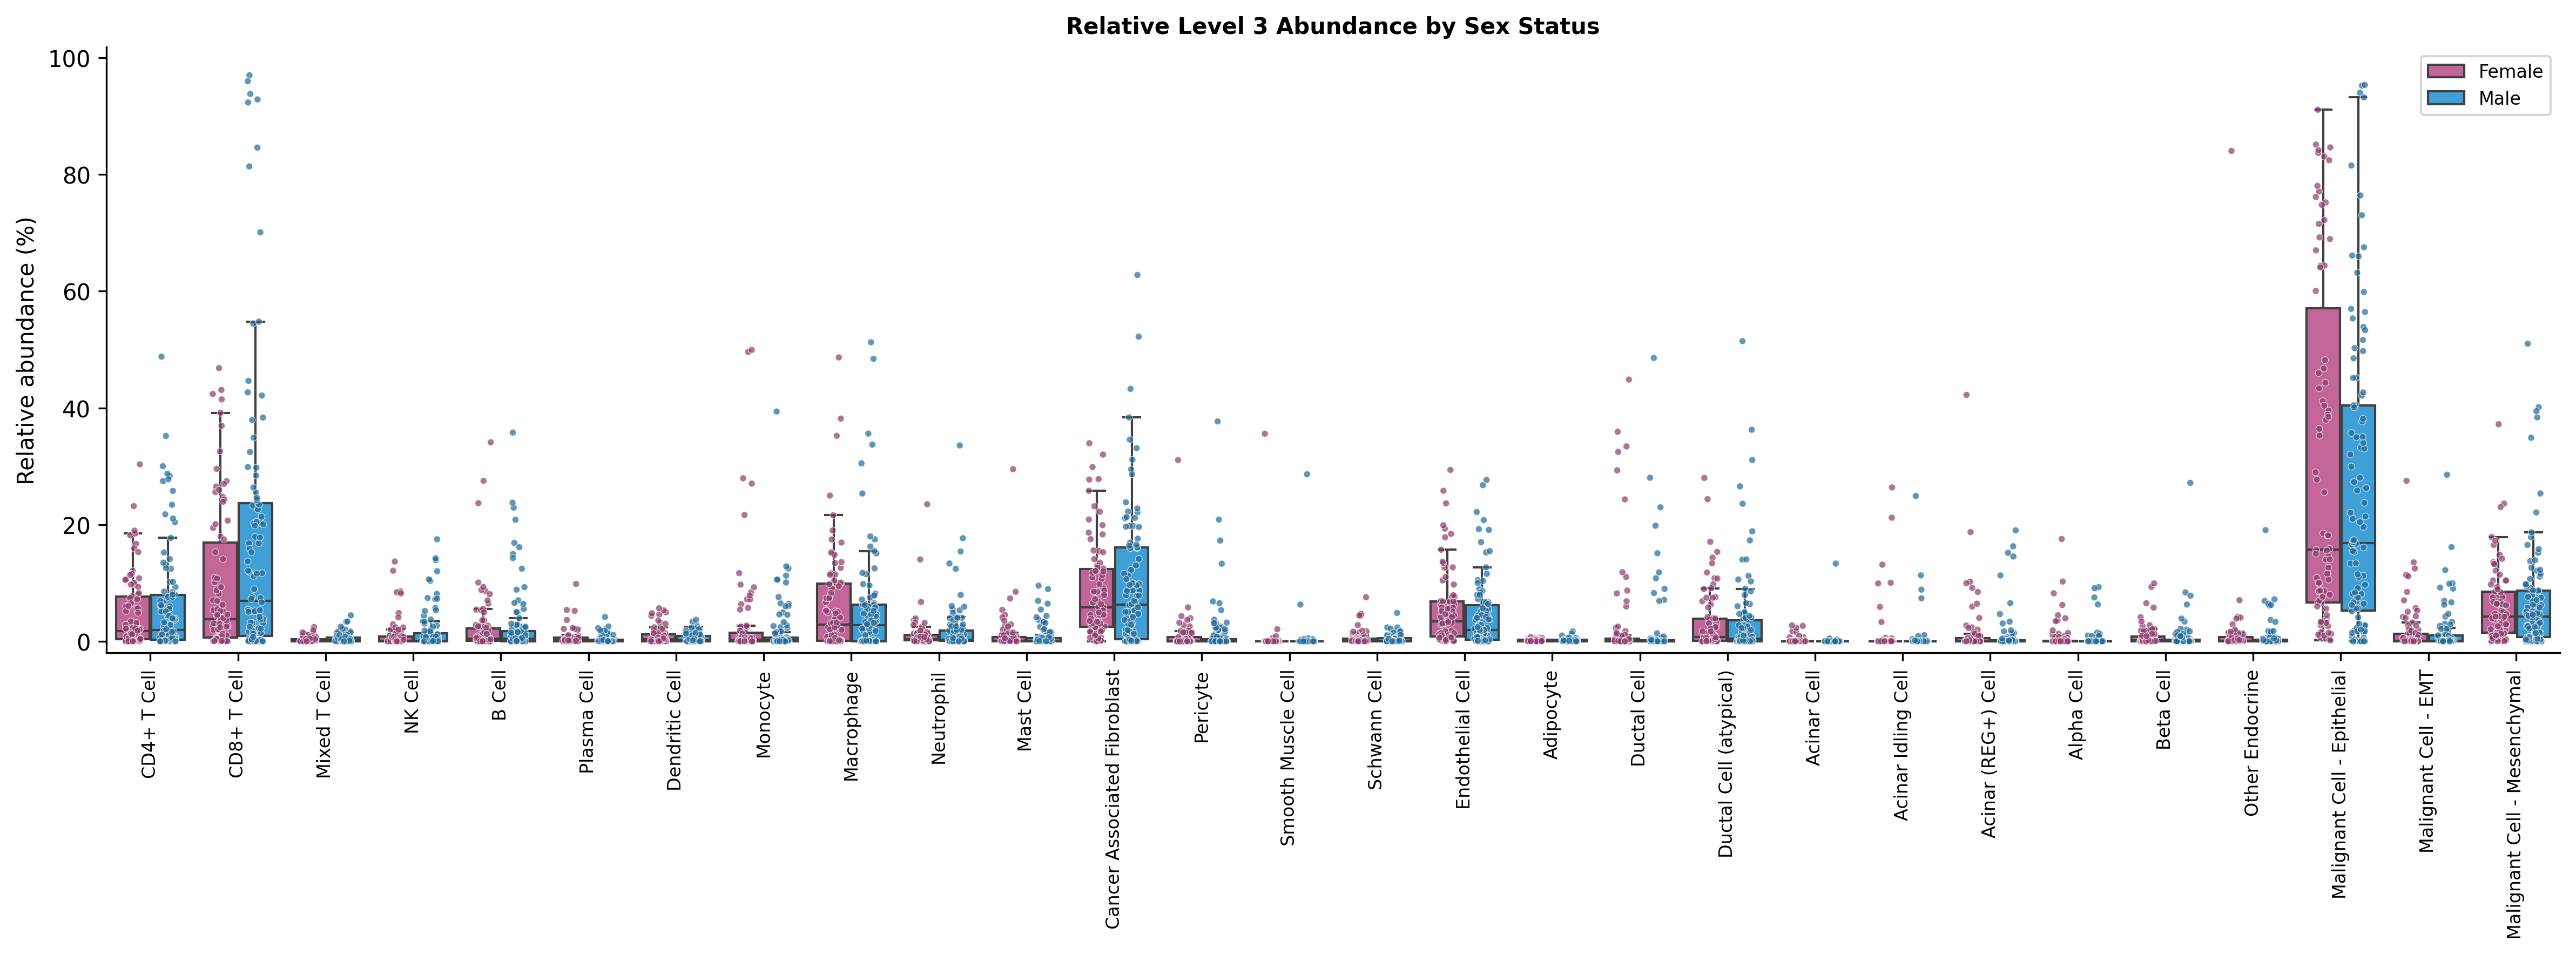

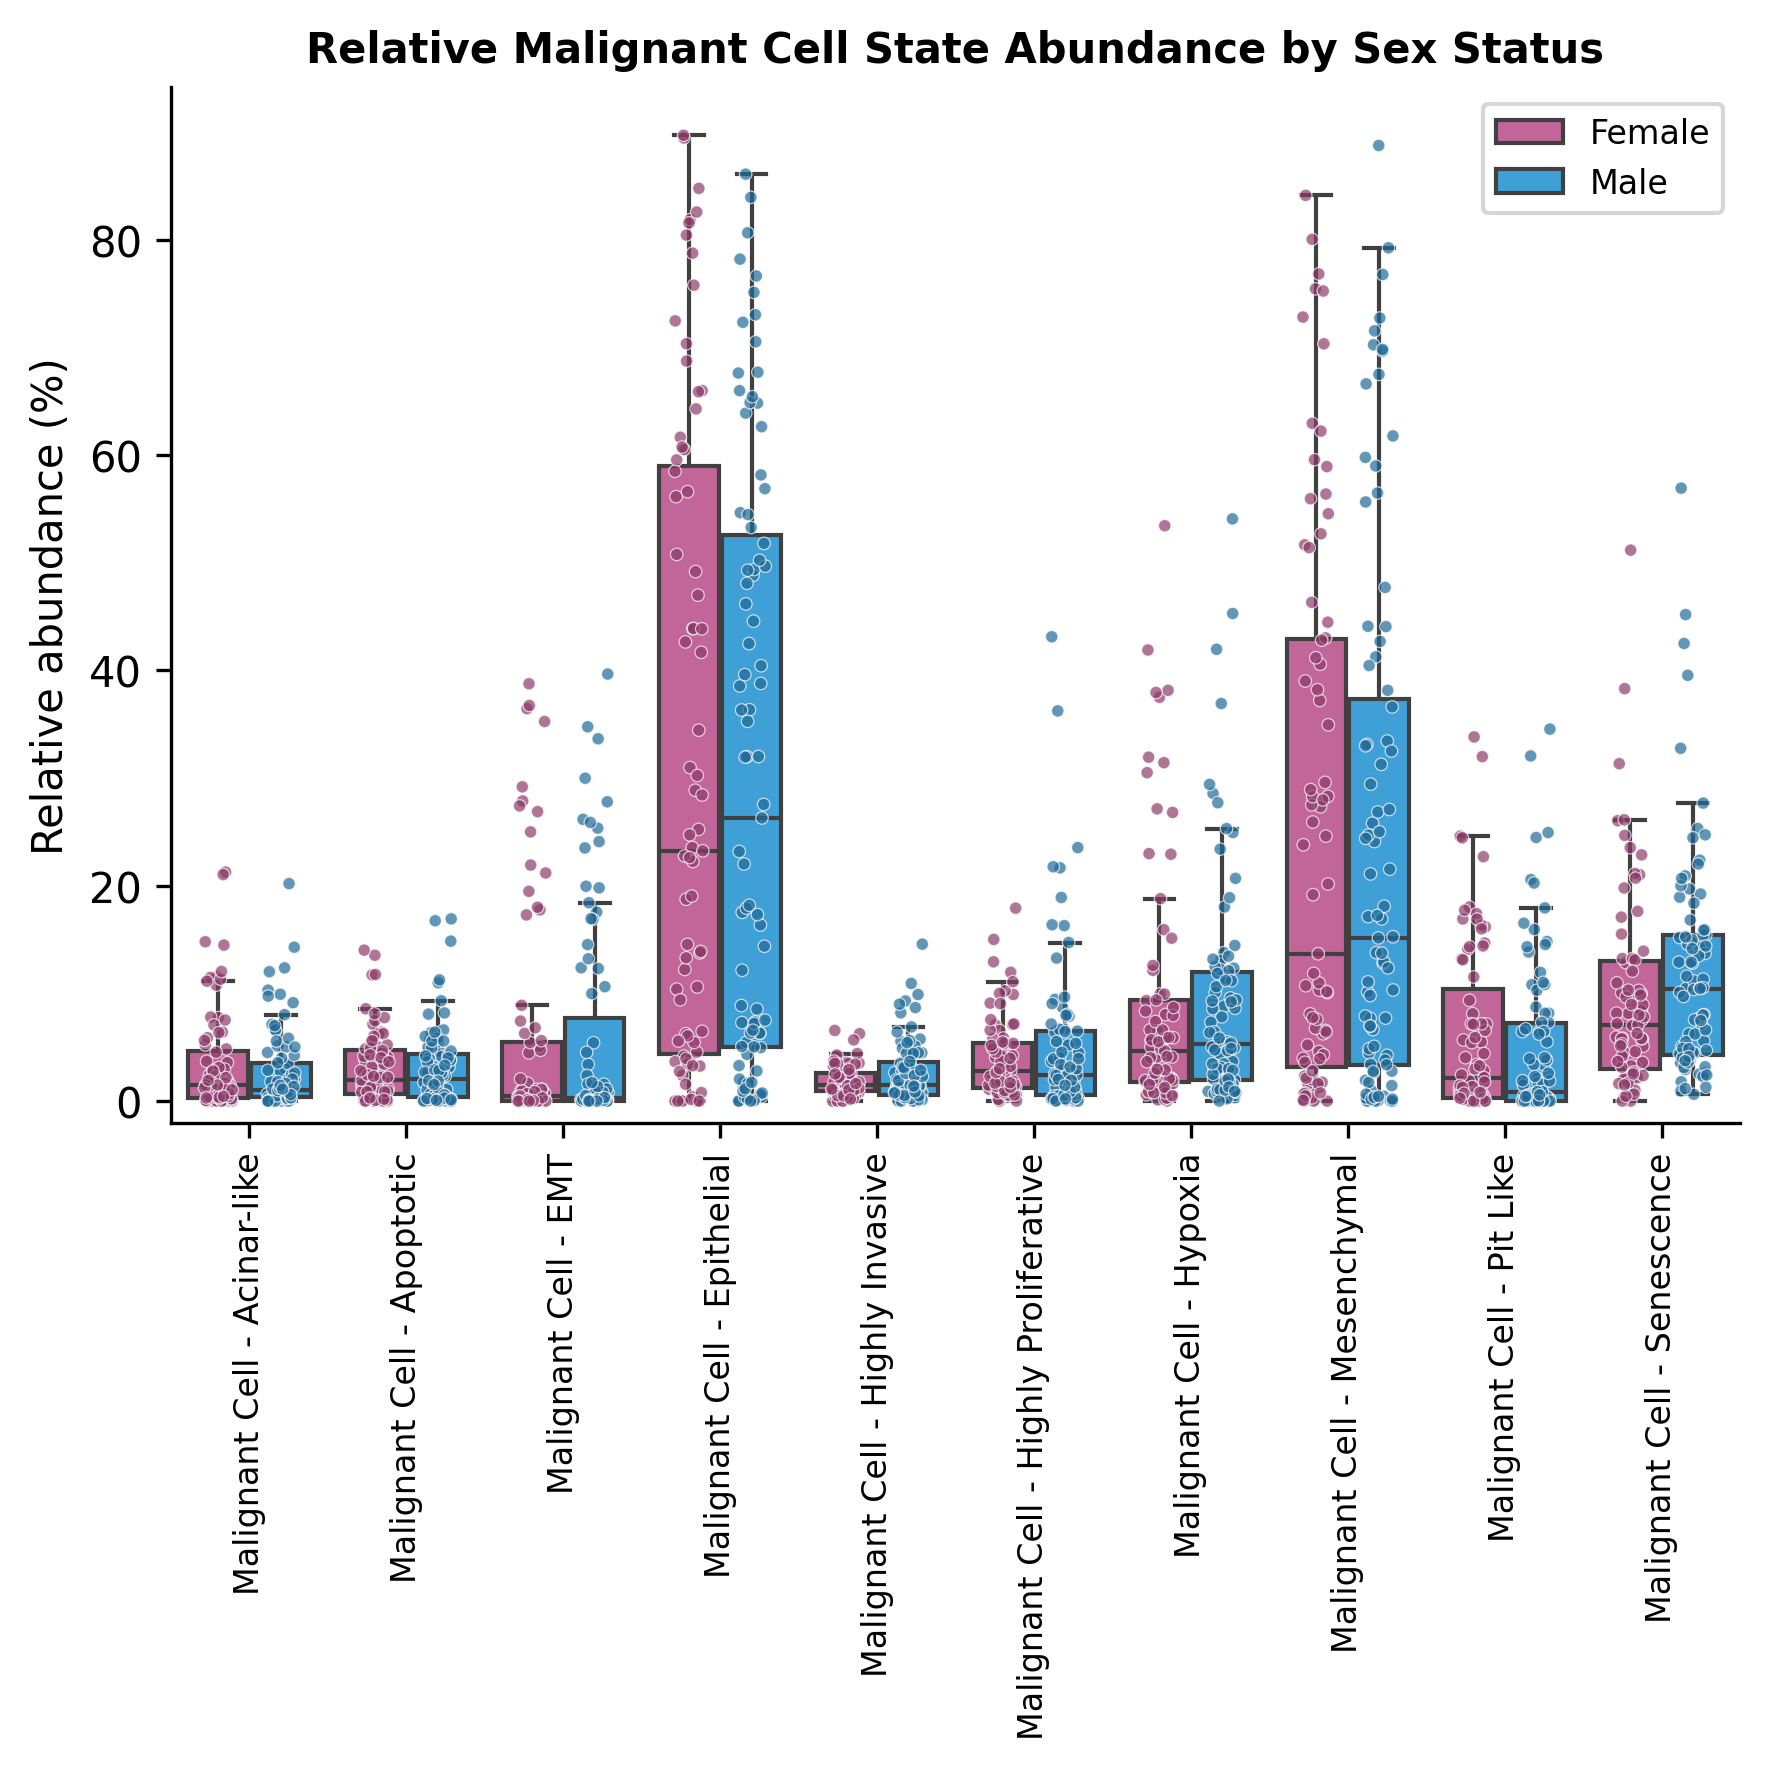

In [ ]:
#split in to different plots for level 3 and malignant level 4 states

def plot_sex_composition(props, title, figsize):
    plot_data = props.mul(100).assign(Sex=sex_of.reindex(props.index))
    plot_data = plot_data[plot_data["Sex"].isin(["Female", "Male"])]

    long = plot_data.melt(
        id_vars="Sex", var_name="Cell type", value_name="Abundance"
    )

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    sns.boxplot(
        data=long,
        x="Cell type",
        y="Abundance",
        hue="Sex",
        order=props.columns,
        hue_order=["Female", "Male"],
        palette={"Female": "#c2669a", "Male": "#3fa0d8"},
        showfliers=False,
        width=0.8, gap=0.05, saturation=1,
        linewidth=1, linecolor="0.25",
        ax=ax,
    )
    sns.stripplot(
        data=long,
        x="Cell type",
        y="Abundance",
        hue="Sex",
        order=props.columns,
        hue_order=["Female", "Male"],
        palette={"Female": "#8c3a6a", "Male": "#1f6a99"},
        dodge=True, jitter=0.18, size=3, alpha=0.7,
        edgecolor="white", linewidth=0.3,
        legend=False, zorder=3,
        ax=ax,
    )
    ax.set_title(f"Relative {title} Abundance by Sex Status", fontweight="bold", loc="center", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Relative abundance (%)")
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.set_ylim(bottom=-2)
    ax.legend(title=None, loc="upper right", fontsize=8)
    sns.despine(ax=ax)
    fig.tight_layout()
    plt.show()


plot_sex_composition(props_l3, "Level 3", (16, 6))
plot_sex_composition(props_mal, "Malignant Cell State", (6, 6))